CIFAR-10_Classification_Using_FFNN_with_Different_Optimization_Techniques.py

In [1]:
import tensorflow as tf
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

I0000 00:00:1792565135.173387    3640 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792565135.932732    3640 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792565138.175374    3640 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
# 1. Load CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = cifar10.load_data()


# 2. Normalize images
x_train = x_train / 255.0
x_test = x_test / 255.0


# 3. One-hot encode labels
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

In [3]:
# 4. CIFAR-10 class names
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]


# 5. Create FFNN with THREE hidden layers
def create_model(units, activation):

    model = Sequential([
        Flatten(input_shape=(32, 32, 3)),

        Dense(units[0], activation=activation),
        Dense(units[1], activation=activation),
        Dense(units[2], activation=activation),

        Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


# 6. Hyperparameters
hidden_units_list = [
    (1024, 512, 256),
    (256, 128, 64),
    (128, 64, 32)
]


# Test ALL three activation functions
activation_list = ['relu', 'tanh', 'sigmoid']


# 7. Store results
results = []

best_accuracy = 0
best_model = None
best_config = None

In [4]:
# 8. Train all configurations
model_number = 1

for units in hidden_units_list:

    for activation in activation_list:

        print("\n========================================")
        print("Training Model", model_number)
        print("Hidden Layers:", units)
        print("Activation:", activation)
        print("========================================")

        model = create_model(units, activation)


        # Train model
        model.fit(
            x_train,
            y_train,
            epochs=5,
            batch_size=64,
            verbose=1
        )


        # Evaluate model
        loss, accuracy = model.evaluate(
            x_test,
            y_test,
            verbose=0
        )

        print("Test Loss:", loss)
        print("Test Accuracy:", accuracy)


        # Store results
        results.append({
            "Model": model_number,
            "Hidden Layers": units,
            "Activation": activation,
            "Test Loss": loss,
            "Test Accuracy": accuracy
        })


        # Find best model
        if accuracy > best_accuracy:
            best_accuracy = accuracy
            best_model = model
            best_config = (units, activation)


        model_number += 1


# 9. Display ALL model configurations
print("\n\n========================================")
print("CONFIGURATION OF ALL MODELS")
print("========================================")

for result in results:

    print("\nModel:", result["Model"])
    print("Hidden Layers :", result["Hidden Layers"])
    print("Activation    :", result["Activation"])
    print("Test Loss     :", round(result["Test Loss"], 4))
    print("Test Accuracy :", round(result["Test Accuracy"], 4))


# 10. Display best model
print("\n\n========================================")
print("              BEST MODEL")
print("========================================")

print("Hidden Layers :", best_config[0])
print("Activation    :", best_config[1])
print("Best Accuracy :", round(best_accuracy, 4))


Training Model 1
Hidden Layers: (1024, 512, 256)
Activation: relu


/home/vaishakh/Projects/Deep-Learning-Lab/.venv/lib/python3.11/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
E0000 00:00:1792565142.670905    3640 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/5


W0000 00:00:1792565144.073306    3640 cpu_allocator_impl.cc:82] Allocation of 614400000 exceeds 10% of free system memory.


782/782 ━━━━━━━━━━━━━━━━━━━━ 21s 25ms/step - accuracy: 0.3222 - loss: 1.8680
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 22s 28ms/step - accuracy: 0.3976 - loss: 1.6725
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 20s 25ms/step - accuracy: 0.4357 - loss: 1.5754
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 19s 25ms/step - accuracy: 0.4552 - loss: 1.5197
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 19s 25ms/step - accuracy: 0.4722 - loss: 1.4755


W0000 00:00:1792565246.316872    3640 cpu_allocator_impl.cc:82] Allocation of 122880000 exceeds 10% of free system memory.


... (3 outputs left out)

W0000 00:00:1792565350.835855    3640 cpu_allocator_impl.cc:82] Allocation of 122880000 exceeds 10% of free system memory.


Test Loss: 1.9191009998321533
Test Accuracy: 0.28690001368522644

Training Model 3
Hidden Layers: (1024, 512, 256)
Activation: sigmoid
Epoch 1/5


W0000 00:00:1792565352.836301    3640 cpu_allocator_impl.cc:82] Allocation of 614400000 exceeds 10% of free system memory.


782/782 ━━━━━━━━━━━━━━━━━━━━ 22s 27ms/step - accuracy: 0.3026 - loss: 1.9051
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 20s 25ms/step - accuracy: 0.3726 - loss: 1.7306
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 20s 25ms/step - accuracy: 0.3919 - loss: 1.6758
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 20s 25ms/step - accuracy: 0.4116 - loss: 1.6378
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 20s 25ms/step - accuracy: 0.4211 - loss: 1.6015
Test Loss: 1.567490816116333
Test Accuracy: 0.43309998512268066

Training Model 4
Hidden Layers: (256, 128, 64)
Activation: relu
Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.3169 - loss: 1.8919
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.3885 - loss: 1.6991
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.4238 - loss: 1.6092
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.4463 - loss: 1.5470
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.4583 - loss: 1.5137
Test Loss: 1.51632571


Predicted Label: Deer
Actual Label   : Deer


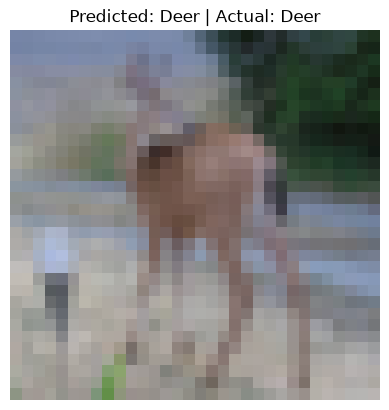

In [5]:
# 11. Predict one test image
index = 100

prediction = best_model.predict(
    x_test[index:index + 1],
    verbose=0
)

predicted_class = prediction.argmax()
actual_class = y_test[index].argmax()

print("\nPredicted Label:", class_names[predicted_class])
print("Actual Label   :", class_names[actual_class])


# 12. Display the image
plt.imshow(x_test[index])

plt.title(
    "Predicted: " + class_names[predicted_class] +
    " | Actual: " + class_names[actual_class]
)

plt.axis('off')
plt.show()